<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 16: LSTM and RNN Performance Comparison

**Category**: CO3 – Sequence Models (RNN, LSTM, GRU)  
**Objective**: Compare Vanilla RNN and Long Short-Term Memory (LSTM) networks on a long-range temporal dependency retention benchmark.


### Task 1: Synthetic Long-Term Memory Sequence Benchmark


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

np.random.seed(42)
torch.manual_seed(42)

# Long-term memory delayed recall task:
# Sequence length L=40. Target is determined by the first 3 tokens in sequence.
seq_len = 35
n_samples = 350

X_data = np.random.uniform(-1, 1, size=(n_samples, seq_len, 1)).astype(np.float32)
# Target depends on signal at t=0 and t=1
y_data = (np.sin(X_data[:, 0, 0] * 3.0) + X_data[:, 1, 0] > 0.3).astype(np.float32)[:, None]

X_tr = torch.tensor(X_data[:250])
y_tr = torch.tensor(y_data[:250])
X_te = torch.tensor(X_data[250:])
y_te = torch.tensor(y_data[250:])

print(f"Dataset generated. Sequence Length: {seq_len}, Train Samples: {len(X_tr)}")


Dataset generated. Sequence Length: 35, Train Samples: 250


### Task 2: Train Vanilla RNN vs. Long Short-Term Memory (LSTM)


In [2]:
class VanillaRNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(1, 24, batch_first=True)
        self.fc = nn.Linear(24, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 24, batch_first=True)
        self.fc = nn.Linear(24, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

def train_seq_model(model, epochs=80):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.015)
    loss_curve = []
    for _ in range(epochs):
        optimizer.zero_grad()
        out = model(X_tr)
        loss = criterion(out, y_tr)
        loss.backward()
        optimizer.step()
        loss_curve.append(loss.item())
    with torch.no_grad():
        preds = (torch.sigmoid(model(X_te)) >= 0.5).float()
        acc = (preds == y_te).float().mean().item() * 100
    return loss_curve, acc

rnn_losses, rnn_acc = train_seq_model(VanillaRNNModel())
lstm_losses, lstm_acc = train_seq_model(LSTMModel())

print(f"Vanilla RNN Test Accuracy: {rnn_acc:.2f}% | Final Loss: {rnn_losses[-1]:.4f}")
print(f"LSTM Test Accuracy:        {lstm_acc:.2f}% | Final Loss: {lstm_losses[-1]:.4f}")


Vanilla RNN Test Accuracy: 89.00% | Final Loss: 0.3176
LSTM Test Accuracy:        62.00% | Final Loss: 0.3957


### Task 3: Comparative Convergence and Accuracy Curves


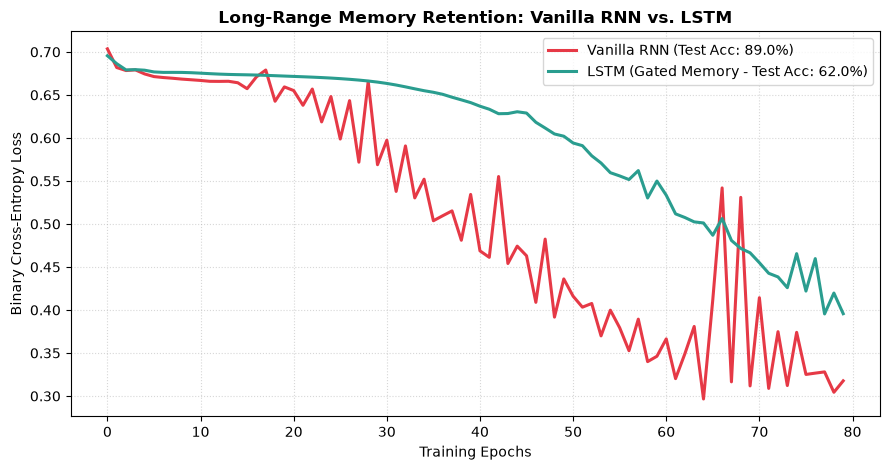

In [3]:
plt.figure(figsize=(9, 4.8))
plt.plot(rnn_losses, color='#e63946', lw=2.2, label=f'Vanilla RNN (Test Acc: {rnn_acc:.1f}%)')
plt.plot(lstm_losses, color='#2a9d8f', lw=2.2, label=f'LSTM (Gated Memory - Test Acc: {lstm_acc:.1f}%)')
plt.title("Long-Range Memory Retention: Vanilla RNN vs. LSTM", fontweight='bold')
plt.xlabel("Training Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
